In [1]:
from pathlib import Path
import pandas as pd

PROCESSED_DATA_DIR = Path("../data/processed")

games_raw = pd.read_csv(PROCESSED_DATA_DIR / "games_raw.csv", low_memory=False)
print(games_raw.shape)

(19824, 358)


In [2]:
feature_columns = [
    "kills", "deaths", "assists", "challenges.killParticipation",
    "totalMinionsKilled", "neutralMinionsKilled", "goldEarned", "champExperience",
    "visionScore", "wardsPlaced", "wardsKilled", "detectorWardsPlaced", "item6",
    "totalDamageDealtToChampions", "challenges.teamDamagePercentage",
    "challenges.dragonTakedowns", "challenges.baronTakedowns", "challenges.riftHeraldTakedowns",
    "challenges.voidMonsterKill", "challenges.turretTakedowns", "damageDealtToBuildings",
    "totalHealsOnTeammates", "totalDamageShieldedOnTeammates",
    "roleBoundItem",
    "summonerLevel", "ladder.wins", "ladder.losses",
    "win",
]

ping_columns = [
    "enemyMissingPings",
    "allInPings", "assistMePings", "basicPings", "commandPings", "dangerPings",
    "enemyVisionPings", "getBackPings", "holdPings", "needVisionPings",
    "onMyWayPings", "pushPings", "retreatPings", "visionClearedPings",
]

label_columns = ["ladder.tier", "ladder.division"]

grouping_columns = [
    "teamPosition", "championName", "ladder.server",
    "match.gameDuration", "match.gameVersion",
]

edge_case_columns = [
    "gameEndedInEarlySurrender", "gameEndedInSurrender",
    "teamEarlySurrendered", "teamIGNBSurrendered",
    "wasAfk", "challenges.hadAfkTeammate", "wasSevereTransgressor",
    "positionAssignedByMatchmaking", "selectedRolePreferences",
    "ladder.veteran", "ladder.freshBlood", "ladder.hotStreak",
]

key_columns = ["puuid", "match.matchId", "match.gameEndTimestamp", "timePlayed"]

kept_columns = (feature_columns + ping_columns + label_columns
                + grouping_columns + edge_case_columns + key_columns)

missing_columns = [column for column in kept_columns if column not in games_raw.columns]
print("Missing columns:", missing_columns)

games = games_raw[kept_columns].copy()
print(games.shape)

Missing columns: []
(19824, 65)


In [3]:
duplicate_game_rows = games.duplicated(subset=["puuid", "match.matchId"]).sum()
print("Duplicate (player, game) rows:", duplicate_game_rows)

missing_value_counts = games.isna().sum()
print(missing_value_counts[missing_value_counts > 0].sort_values(ascending=False))

Duplicate (player, game) rows: 0
challenges.hadAfkTeammate          19418
challenges.killParticipation         397
challenges.teamDamagePercentage       34
teamPosition                           2
dtype: int64


In [4]:
print(games["selectedRolePreferences"].value_counts().head(10))
print()
print(games["positionAssignedByMatchmaking"].value_counts())
print()
print(games.loc[games["challenges.teamDamagePercentage"].isna(),
                ["match.gameDuration", "gameEndedInEarlySurrender", "kills", "deaths"]].describe())

selectedRolePreferences
UTILITY.PRIMARY.UTILITY.MIDDLE       1389
BOTTOM.PRIMARY.BOTTOM.MIDDLE.FILL    1311
JUNGLE.PRIMARY.JUNGLE.MIDDLE         1276
MIDDLE.PRIMARY.MIDDLE.BOTTOM.FILL    1033
TOP.PRIMARY.TOP.MIDDLE                998
TOP.PRIMARY.TOP.MIDDLE.FILL           957
UTILITY.PRIMARY.UTILITY.BOTTOM        913
MIDDLE.PRIMARY.MIDDLE.BOTTOM          780
BOTTOM.PRIMARY.BOTTOM.MIDDLE          757
MIDDLE.PRIMARY.MIDDLE.TOP.FILL        617
Name: count, dtype: int64

positionAssignedByMatchmaking
UTILITY    4330
MIDDLE     4116
BOTTOM     3973
TOP        3752
JUNGLE     3653
Name: count, dtype: int64

       match.gameDuration  kills  deaths
count           34.000000   34.0    34.0
mean            68.588235    0.0     0.0
std              8.090839    0.0     0.0
min             30.000000    0.0     0.0
25%             67.000000    0.0     0.0
50%             69.000000    0.0     0.0
75%             71.000000    0.0     0.0
max             88.000000    0.0     0.0


In [5]:
role_preference_parts = games["selectedRolePreferences"].str.split(".", expand=True)

# Does part 1 always match the role matchmaking assigned?
part1_matches_assigned = (role_preference_parts[0] == games["positionAssignedByMatchmaking"]).mean()
print("Part 1 matches assigned role:", round(part1_matches_assigned, 4))

# What values does part 2 take?
print(role_preference_parts[1].value_counts())

Part 1 matches assigned role: 0.9767
1
PRIMARY           16533
SECONDARY          1803
AUTOFILL           1079
FILL_PRIMARY        347
FILL_SECONDARY       62
Name: count, dtype: int64


In [6]:
# selectedRolePreferences looks like "UTILITY.PRIMARY.UTILITY.MIDDLE"
# Part 1 = role the player got, part 2 = how they got it,
# part 3 = first choice, part 4 = second choice, part 5 = sometimes FILL
role_preference_parts = games["selectedRolePreferences"].str.split(".", expand=True)

# How the player got their role: PRIMARY, SECONDARY, AUTOFILL, FILL_PRIMARY, FILL_SECONDARY
games["role_assignment"] = role_preference_parts[1]

# Remake: early vote, usually because someone is AFK or disconnected
games["is_remake"] = games["gameEndedInEarlySurrender"].astype(bool)

# Normal surrender vote
games["is_surrender"] = games["gameEndedInSurrender"].astype(bool)

# IGNB surrender type (undocumented by Riot)
games["is_ignb"] = games["teamIGNBSurrendered"].astype(bool)

# Riot's flag: the sampled player was AFK
games["player_afk"] = games["wasAfk"].astype(bool)

# A teammate was AFK; the column is blank when no one was, so blank becomes 0
games["teammate_afk"] = games["challenges.hadAfkTeammate"].fillna(0) > 0

# Riot's flag for serious misconduct: griefing or intentional feeding
games["griefer"] = games["wasSevereTransgressor"].astype(bool)

# Got neither of the two roles they queued for
games["autofilled"] = games["role_assignment"] == "AUTOFILL"

# No role recorded for this player
games["no_role"] = games["teamPosition"].isna()

flag_columns = ["is_remake", "is_surrender", "is_ignb", "player_afk",
                "teammate_afk", "griefer", "autofilled", "no_role"]

# Count table for the report: how many games each flag marks
flag_counts = pd.DataFrame({
    "games_flagged": games[flag_columns].sum(),
    "percent_of_games": (games[flag_columns].mean() * 100).round(2),
})
print(flag_counts)

# The ~2.3% of games where part 1 doesn't match positionAssignedByMatchmaking:
# show which role_assignment values they have, so the report can explain them
part1_mismatch = role_preference_parts[0] != games["positionAssignedByMatchmaking"]
print("\nMismatched games by role_assignment:")
print(games.loc[part1_mismatch, "role_assignment"].value_counts())

              games_flagged  percent_of_games
is_remake               425              2.14
is_surrender           5545             27.97
is_ignb                  15              0.08
player_afk              146              0.74
teammate_afk            406              2.05
griefer                   1              0.01
autofilled             1079              5.44
no_role                   2              0.01

Mismatched games by role_assignment:
role_assignment
AUTOFILL          180
PRIMARY           151
SECONDARY         121
FILL_PRIMARY        6
FILL_SECONDARY      4
Name: count, dtype: int64


In [7]:
import requests

# Game length in minutes, the base for every per-minute rate
games["minutes"] = games["match.gameDuration"] / 60

# Total farming: lane CS + jungle CS
games["total_cs"] = games["totalMinionsKilled"] + games["neutralMinionsKilled"]

# Pings: the "?" ping kept apart, the other 13 summed
games["enemy_missing_pings"] = games["enemyMissingPings"]
info_ping_columns = [column for column in ping_columns if column != "enemyMissingPings"]
games["info_pings"] = games[info_ping_columns].sum(axis=1)

# Item names from Riot's official item list, to read item6 and roleBoundItem
DDRAGON_VERSION = "16.20.1"
item_json = requests.get(
    f"https://ddragon.leagueoflegends.com/cdn/{DDRAGON_VERSION}/data/en_US/item.json"
).json()["data"]
item_names = {int(item_id): item["name"] for item_id, item in item_json.items()}

# 1 if the trinket at game end was Oracle Lens
games["ended_with_oracle"] = (games["item6"].map(item_names) == "Oracle Lens").astype(int)

# 1 if the role quest slot holds a reward; names ending in "Quest" mean unfinished
role_item_names = games["roleBoundItem"].map(item_names)
games["role_quest_completed"] = (
    role_item_names.notna() & ~role_item_names.str.endswith("Quest", na=False)
).astype(int)

# Season totals from the ladder
games["season_games"] = games["ladder.wins"] + games["ladder.losses"]
games["season_wr"] = games["ladder.wins"] / games["season_games"]

# Tier as a number: Iron 0 to Challenger 9
tier_order = ["IRON", "BRONZE", "SILVER", "GOLD", "PLATINUM", "EMERALD",
              "DIAMOND", "MASTER", "GRANDMASTER", "CHALLENGER"]
games["tier_index"] = games["ladder.tier"].map({tier: index for index, tier in enumerate(tier_order)})

# Kill participation is blank when the team had 0 kills; the player took part in 0 of 0
games["challenges.killParticipation"] = games["challenges.killParticipation"].fillna(0)

# Per-minute versions of every count stat
count_columns = [
    "kills", "deaths", "assists",
    "totalMinionsKilled", "neutralMinionsKilled", "total_cs", "goldEarned", "champExperience",
    "visionScore", "wardsPlaced", "wardsKilled", "detectorWardsPlaced",
    "totalDamageDealtToChampions", "damageDealtToBuildings",
    "challenges.dragonTakedowns", "challenges.baronTakedowns", "challenges.riftHeraldTakedowns",
    "challenges.voidMonsterKill", "challenges.turretTakedowns",
    "totalHealsOnTeammates", "totalDamageShieldedOnTeammates",
    "enemy_missing_pings", "info_pings",
]
for column in count_columns:
    games[column + "_per_min"] = games[column] / games["minutes"]

print(games.shape)
print(games[["ended_with_oracle", "role_quest_completed"]].mean().round(3))
print(games["tier_index"].value_counts().sort_index())

(19824, 106)
ended_with_oracle       0.399
role_quest_completed    0.962
dtype: float64
tier_index
0    1710
1    1526
2    1466
3    1445
4    1672
5    1539
6    2366
7    2700
8    2700
9    2700
Name: count, dtype: int64


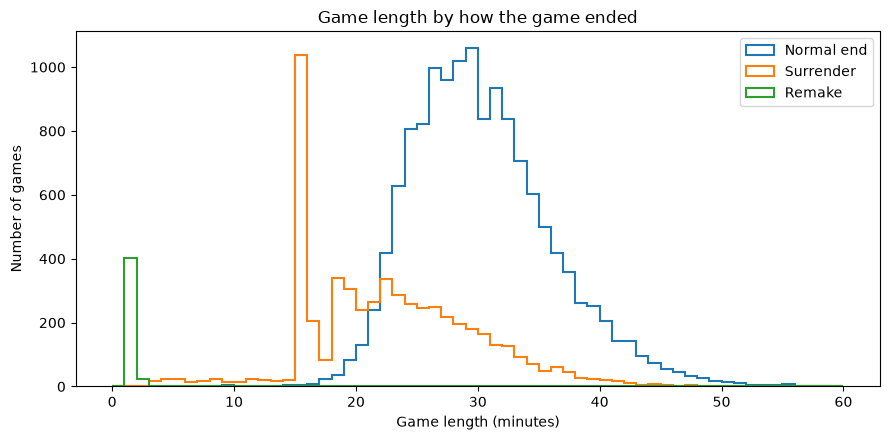

count    5545.0
mean       22.7
std         7.2
min         3.1
25%        16.5
50%        22.2
75%        27.4
max       107.4
Name: minutes, dtype: float64


In [8]:
import matplotlib.pyplot as plt

FIGURES_DIR = Path("../figures")

# Label each game by how it ended
game_ending = pd.Series("Normal end", index=games.index)
game_ending[games["is_surrender"]] = "Surrender"
game_ending[games["is_remake"]] = "Remake"

figure, axis = plt.subplots(figsize=(9, 4.5))
minute_bins = range(0, 61)
for ending_type in ["Normal end", "Surrender", "Remake"]:
    axis.hist(games.loc[game_ending == ending_type, "minutes"],
              bins=minute_bins, histtype="step", linewidth=1.5, label=ending_type)

axis.set_xlabel("Game length (minutes)")
axis.set_ylabel("Number of games")
axis.set_title("Game length by how the game ended")
axis.legend()
figure.tight_layout()
figure.savefig(FIGURES_DIR / "game_length_by_ending.png", dpi=150)
plt.show()

# Shortest surrenders, to see where real games start
print(games.loc[games["is_surrender"], "minutes"].describe().round(1))

In [9]:
# Surrenders before the normal 15-minute vote opens, from the plot above
games["short_surrender"] = games["is_surrender"] & (games["minutes"] < 15)
flag_columns.append("short_surrender")

games.to_csv(PROCESSED_DATA_DIR / "games_clean.csv", index=False)
print(games.shape)
print("Short surrenders:", games["short_surrender"].sum())

(19824, 107)
Short surrenders: 222


In [10]:
pd.set_option("display.max_columns", 120)
games.head(20)

,kills,deaths,assists,challenges.killParticipation,totalMinionsKilled,neutralMinionsKilled,goldEarned,champExperience,visionScore,wardsPlaced,wardsKilled,detectorWardsPlaced,item6,totalDamageDealtToChampions,challenges.teamDamagePercentage,challenges.dragonTakedowns,challenges.baronTakedowns,challenges.riftHeraldTakedowns,challenges.voidMonsterKill,challenges.turretTakedowns,damageDealtToBuildings,totalHealsOnTeammates,totalDamageShieldedOnTeammates,roleBoundItem,summonerLevel,ladder.wins,ladder.losses,win,enemyMissingPings,allInPings,assistMePings,basicPings,commandPings,dangerPings,enemyVisionPings,getBackPings,holdPings,needVisionPings,onMyWayPings,pushPings,retreatPings,visionClearedPings,ladder.tier,ladder.division,teamPosition,championName,ladder.server,match.gameDuration,match.gameVersion,gameEndedInEarlySurrender,gameEndedInSurrender,teamEarlySurrendered,teamIGNBSurrendered,wasAfk,challenges.hadAfkTeammate,wasSevereTransgressor,positionAssignedByMatchmaking,selectedRolePreferences,ladder.veteran,ladder.freshBlood,ladder.hotStreak,puuid,match.matchId,match.gameEndTimestamp,timePlayed,role_assignment,is_remake,is_surrender,is_ignb,player_afk,teammate_afk,griefer,autofilled,no_role,minutes,total_cs,enemy_missing_pings,info_pings,ended_with_oracle,role_quest_completed,season_games,season_wr,tier_index,kills_per_min,deaths_per_min,assists_per_min,totalMinionsKilled_per_min,neutralMinionsKilled_per_min,total_cs_per_min,goldEarned_per_min,champExperience_per_min,visionScore_per_min,wardsPlaced_per_min,wardsKilled_per_min,detectorWardsPlaced_per_min,totalDamageDealtToChampions_per_min,damageDealtToBuildings_per_min,challenges.dragonTakedowns_per_min,challenges.baronTakedowns_per_min,challenges.riftHeraldTakedowns_per_min,challenges.voidMonsterKill_per_min,challenges.turretTakedowns_per_min,totalHealsOnTeammates_per_min,totalDamageShieldedOnTeammates_per_min,enemy_missing_pings_per_min,info_pings_per_min,short_surrender
0,7,10,9,0.516129,34,116,12100,15157,42,14,3,1,3340,21625,0.183452,1,0,0,0,1,1500,266,0,1209,242,113,131,False,8,0,4,0,6,0,0,12,0,0,5,0,0,0,IRON,I,JUNGLE,Volibear,na1,2207,16.20.824.8524,False,True,False,False,False,NaN,False,JUNGLE,JUNGLE.SECONDARY.BOTTOM.JUNGLE,False,True,False,HteuVt6pK9NplkL-c9RNODytZwUcZCwA7Qw0AgVtY8z07t...,NA1_5658049397,1791690086911,2207,SECONDARY,False,True,False,False,False,False,False,False,36.783333,150,8,27,0,1,244,0.463115,0,0.190304,0.271862,0.244676,0.924332,3.153602,4.077934,328.953330,412.061622,1.141821,0.380607,0.081559,0.027186,587.902130,40.779338,0.027186,0.000000,0.000000,0.000000,0.027186,7.231536,0.000000,0.217490,0.734028,False
1,3,4,4,0.368421,97,0,7526,8654,25,9,3,2,3340,9073,0.103195,0,0,0,0,0,0,0,0,3006,242,113,131,False,0,0,0,0,18,0,0,11,0,0,3,0,0,0,IRON,I,BOTTOM,Twitch,na1,1444,16.20.824.8524,False,False,False,False,False,NaN,False,BOTTOM,BOTTOM.PRIMARY.BOTTOM.JUNGLE,False,True,False,HteuVt6pK9NplkL-c9RNODytZwUcZCwA7Qw0AgVtY8z07t...,NA1_5657407734,1791603848962,1444,PRIMARY,False,False,False,False,False,False,False,False,24.066667,97,0,32,0,1,244,0.463115,0,0.124654,0.166205,0.166205,4.030471,0.000000,4.030471,312.714681,359.584488,1.038781,0.373961,0.124654,0.083102,376.994460,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.329640,False
2,0,5,0,0.000000,46,0,3232,4381,17,6,3,2,3340,3374,0.146147,0,0,0,0,0,0,0,0,1202,242,113,131,False,0,0,0,0,0,0,0,5,0,0,0,0,0,0,IRON,I,BOTTOM,Smolder,na1,942,16.20.824.8524,False,True,False,False,False,NaN,False,BOTTOM,BOTTOM.PRIMARY.BOTTOM.JUNGLE,False,True,False,HteuVt6pK9NplkL-c9RNODytZwUcZCwA7Qw0AgVtY8z07t...,NA1_5657396926,1791602059973,942,PRIMARY,False,True,False,False,False,False,False,False,15.700000,46,0,5,0,0,244,0.463115,0,0.000000,0.318471,0.000000,2.929936,0.000000,2.929936,205.859873,279.044586,1.082803,0.382166,0.191083,0.127389,214.904459,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.318471,False
3,7,4,8,0.517241,126,4,10590,13700,33,13,4,3,33